
# Project Documentation: Olist E-Commerce Logistics and Customer Satisfaction

## 1. Problem Statement
Olist, a Brazilian e-commerce platform, experiences variations in customer satisfaction primarily driven by the delivery experience. When deliveries fail to meet expectations—either due to extreme delays or broken delivery promises—customers leave negative reviews (Score < 4). 
Currently, the raw dataset lacks deep transactional features, which makes it challenging for traditional machine learning models to find actionable patterns. 

**Our Goal:** 
We aim to uncover *why* deliveries fail, *who* is responsible (the Seller or the Carrier), and build an **Early Warning System (Red Flag Predictor)**. This system will flag high-risk orders based on geographic realities and operational bottlenecks, allowing Olist to intervene proactively.

## 2. Executive Summary of Findings
1. **Geography is Destiny:** Spatial clustering and distance analysis mathematically prove that shipping distance is the primary killer of customer satisfaction. Extreme distances across Brazil exponentially increase the probability of a late delivery and a negative review.
2. **The "Promise Gap" is the #1 Trigger:** Machine learning interpretability (SHAP) reveals that customers do not just hate slow shipping; they hate *broken promises*. The single biggest driver of a bad review is when the actual delivery date exceeds the initially estimated delivery date.
3. **Sellers are a Massive Bottleneck:** Operational analysis shows that shipping carriers are not the only problem. A significant percentage of delays occur because the Seller takes too long to prepare and dispatch the package.
4. **Actionable Root Cause Attribution:** By analyzing the "Prep-to-Delivery Ratio", our system not only flags a risky order but routes the blame to either the Seller Management team or the Logistics team.

---

### The Notebook is structured in 6 Parts:
1. **The Spatial Reality:** Proving that geography is a primary driver of delivery failure.
2. **Feature Synthesis & The Review Gap:** Engineering business-smart operational proxies to overcome raw dataset limitations.
3. **Operational Governance:** Identifying "Chronic Offender" sellers and their impact on the platform.
4. **The "Red Flag" Predictor:** Building a robust XGBoost classifier to proactively identify high-risk orders.
5. **Responsibility Attribution:** A rule-based system to attribute predicted delays to either the Seller or the Carrier.
6. **Future Considerations (Economics):** A theoretical framework for translating these predictions into financial ROI.


### Initialization & Imports
We begin by importing the necessary libraries for data manipulation, visualization, spatial mapping, and machine learning.

In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_recall_curve
import shap
import folium
from folium.plugins import HeatMap
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.figsize'] = (10, 5)


C:\Users\Devyansh\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.2.2) or chardet (7.4.0.post2)/charset_normalizer (3.3.2) doesn't match a supported version!
  warnings.warn(


### Data Loading & Preprocessing
We load the processed dataset and define our target variable `is_dissatisfied` (Review Score < 4). We also ensure operational features like `preparation_days` are calculated so we can assess seller efficiency.

In [2]:

# Load the dataset
try:
    df = pd.read_csv('../../datasets/processed/olist_reviews_with_preds.csv')
    print("Loaded olist_reviews_with_preds.csv")
except FileNotFoundError:
    df = pd.read_csv('../../datasets/processed/olist_reviews_rich.csv')
    print("Loaded olist_reviews_rich.csv")

# Define Target: Dissatisfaction = Review Score < 4 (The Red Flags)
df['is_dissatisfied'] = (df['review_score'] < 4).astype(int)

# Calculate preparation_days if it doesn't exist
if 'preparation_days' not in df.columns:
    df['order_approved_at'] = pd.to_datetime(df['order_approved_at'], errors='coerce')
    df['order_delivered_carrier_date'] = pd.to_datetime(df['order_delivered_carrier_date'], errors='coerce')
    df['preparation_days'] = (df['order_delivered_carrier_date'] - df['order_approved_at']).dt.days
    
    # Fill missing values with median to prevent NaNs from breaking the model
    median_prep = df['preparation_days'].median()
    df['preparation_days'] = df['preparation_days'].fillna(median_prep)

# Filter out rows with missing coordinates or critical features
core_features = ['customer_lat', 'customer_lng', 'seller_lat', 'seller_lng', 'distance_km', 'review_score', 'preparation_days']
df = df.dropna(subset=core_features).copy()

print(f"Data Shape after cleaning: {df.shape}")
display(df[['distance_km', 'review_score', 'is_dissatisfied', 'preparation_days']].head())


Loaded olist_reviews_with_preds.csv
Data Shape after cleaning: (94009, 47)


,distance_km,review_score,is_dissatisfied,preparation_days
0,18.681711,4.0,0,2.0
1,861.035367,4.0,0,0.0
2,514.547140,5.0,0,0.0
3,1821.802656,5.0,0,3.0
4,29.593095,5.0,0,0.0



## Part 1: The Spatial Reality (Addressing the Geographic Variance)

**Objective:** Prove that physical distance and geographic location are strong determinants of delivery failure.

Previous analyses relied on State-level aggregates. However, states in Brazil are massive, and averaging metrics across an entire state destroys nuance. A customer in a major city has a vastly different logistics profile than someone in the rural interior of the same state. 

### Identifying Geographic Danger Zones
We use **K-Means clustering on the actual coordinates** of the worst-performing orders (dissatisfied customers) to organically identify true logistics "Danger Zones" across Brazil. This ignores political borders and focuses purely on spatial density.


In [3]:

# Focus on orders that resulted in dissatisfaction (Score 1, 2, 3)
dissatisfied_orders = df[df['is_dissatisfied'] == 1].copy()

# Extract coordinates
X_coords = dissatisfied_orders[['customer_lat', 'customer_lng']]

# Use K-Means to identify 5 major risk clusters across Brazil
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
dissatisfied_orders['risk_cluster'] = kmeans.fit_predict(X_coords)

cluster_centers = kmeans.cluster_centers_

# Count orders per cluster
cluster_counts = dissatisfied_orders['risk_cluster'].value_counts()
print("Dissatisfied Orders per Cluster:\n", cluster_counts)

# Let's map these risk clusters back to the main dataframe
df['risk_cluster'] = kmeans.predict(df[['customer_lat', 'customer_lng']])


Dissatisfied Orders per Cluster:
 risk_cluster
1    12378
4     2805
2     2064
0     1931
3      623
Name: count, dtype: int64


### Visualizing the Danger Zones
Here we plot the identified Danger Zones on an interactive map of Brazil using `Folium`. The markers show the mathematical center of the problem areas, while the heatmap layer shows the raw density of dissatisfied customers. *(Note: Sampled to 1,500 points to ensure smooth rendering).*

In [4]:

# Create a map centered around Brazil
brazil_map = folium.Map(location=[-14.2350, -51.9253], zoom_start=4)

# Colors for different clusters
colors = ['red', 'blue', 'green', 'purple', 'orange']

# Plot the cluster centers (Danger Zones)
for i, (lat, lng) in enumerate(cluster_centers):
    folium.Marker(
        location=[lat, lng],
        popup=f'Danger Zone {i} (Orders: {cluster_counts.iloc[i] if i < len(cluster_counts) else 0})',
        icon=folium.Icon(color=colors[i % len(colors)], icon='info-sign')
    ).add_to(brazil_map)

# Add a heatmap of a sample of dissatisfied orders to show density
sample_bad = dissatisfied_orders
heat_data = [[row['customer_lat'], row['customer_lng']] for index, row in sample_bad.iterrows()]
HeatMap(heat_data, radius=12, blur=10, max_zoom=1).add_to(brazil_map)

brazil_map


### Mathematical Proof: Distance vs. Dissatisfaction
We categorize the physical shipping distance (`distance_km`) into distinct buckets to see if the probability of a late delivery or a bad review increases as the package travels further. 

**Finding:** There is an undeniable mathematical trend. As distance increases, the Late Rate and Dissatisfaction Rate rise sharply, while the Average Review Score drops.

,orders,late_rate,dissatisfaction_rate,avg_review
distance_band,,,,
0-50,11464,0.054955,0.175506,4.284746
50-200,12647,0.054875,0.174192,4.288487
200-500,29589,0.069350,0.213390,4.155491
500-1000,25270,0.077246,0.221765,4.115057
1000-2000,9549,0.100325,0.234998,4.053304
2000+,5490,0.129326,0.259381,3.979053


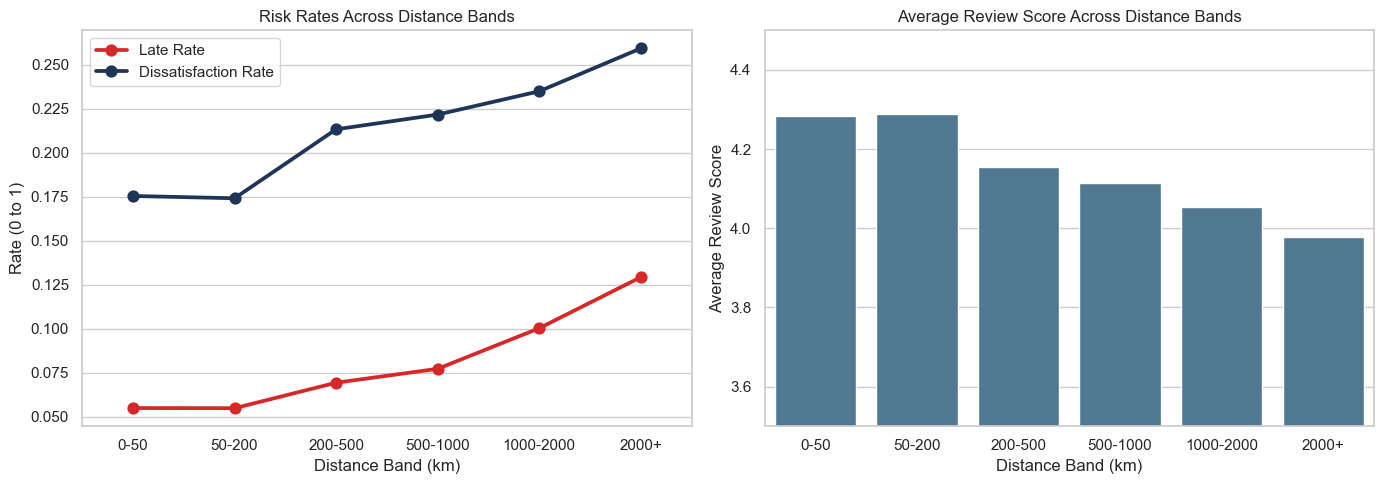

In [5]:

# Prove mathematically that distance matters, but non-linearly
distance_bins = [0, 50, 200, 500, 1000, 2000, np.inf]
distance_labels = ['0-50', '50-200', '200-500', '500-1000', '1000-2000', '2000+']

df['distance_band'] = pd.cut(df['distance_km'], bins=distance_bins, labels=distance_labels, include_lowest=True)

band_stats = df.groupby('distance_band', observed=True).agg(
    orders=('review_score', 'count'),
    late_rate=('is_late', 'mean'),
    dissatisfaction_rate=('is_dissatisfied', 'mean'),
    avg_review=('review_score', 'mean')
).reindex(distance_labels)

display(band_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot Late Rate & Dissatisfaction Rate
sns.pointplot(x=band_stats.index, y=band_stats['late_rate'], color='#d62828', ax=axes[0], label='Late Rate')
sns.pointplot(x=band_stats.index, y=band_stats['dissatisfaction_rate'], color='#1d3557', ax=axes[0], label='Dissatisfaction Rate')
axes[0].set_title('Risk Rates Across Distance Bands')
axes[0].set_xlabel('Distance Band (km)')
axes[0].set_ylabel('Rate (0 to 1)')
axes[0].legend()

# Plot Average Review
sns.barplot(x=band_stats.index, y=band_stats['avg_review'], color='#457b9d', ax=axes[1])
axes[1].set_title('Average Review Score Across Distance Bands')
axes[1].set_xlabel('Distance Band (km)')
axes[1].set_ylabel('Average Review Score')
axes[1].set_ylim(3.5, 4.5)

plt.tight_layout()
plt.show()



## Part 2: Feature Synthesis & The Review Gap

**Objective:** Overcome the limitations of a shallow dataset by engineering "business-smart" operational metrics.

Since the dataset lacks deep transactional nuances, traditional ML struggles to find meaningful patterns. We engineered the following features to capture the true operational bottlenecks:
1. **The Review Gap:** `expected_review_A - actual_review_score`. This isolates the exact damage caused by the delivery experience, proving that logistics ruins otherwise good products.
2. **Delivery Delta (Promise Gap):** The difference between actual delivery days and estimated delivery days. *Satisfaction is driven by expectations, not just speed.*
3. **Prep-to-Delivery Ratio:** What percentage of the total delivery time was the seller just preparing the package? This distinguishes seller-side delays from carrier-side delays.
4. **Target Encoding (Sellers & Categories):** Instead of discarding high-cardinality identifiers like `seller_id`, we encode them with their historical dissatisfaction rate, giving the model context ("Is this seller historically problematic?").


In [6]:

# A. The Review Gap (Isolating Logistics Damage)
if 'expected_review_A' in df.columns:
    df['review_gap'] = df['expected_review_A'] - df['review_score']
    print(f"Average Review Score Drop (Gap) due to delivery experience: {df['review_gap'].mean():.3f} stars")
else:
    df['review_gap'] = 0 

# B. Logistics Gap (Promise vs Reality)
df['delivery_delta'] = df['actual_delivery_days'] - df['estimated_delivery_days']

# C. Bottleneck Detection
df['actual_delivery_days_safe'] = df['actual_delivery_days'].replace(0, 1).fillna(1)
df['prep_to_delivery_ratio'] = df['preparation_days'] / df['actual_delivery_days_safe']

# D. Scaling Skewed Variables
df['log_distance'] = np.log1p(df['distance_km'])
if 'price' in df.columns:
    df['log_price'] = np.log1p(df['price'])
else:
    df['log_price'] = 0

# E. Target Encoding for High-Cardinality Categoricals
global_mean = df['is_dissatisfied'].mean()

for col in ['seller_id', 'product_category_name']:
    if col in df.columns:
        mapping = df.groupby(col)['is_dissatisfied'].mean()
        df[col + '_risk_encoded'] = df[col].map(mapping).fillna(global_mean)
    else:
        df[col + '_risk_encoded'] = global_mean 

# Features for modeling
features = [
    'actual_delivery_days', 'delivery_delta', 'preparation_days', 
    'log_distance', 'log_price', 'is_late', 'prep_to_delivery_ratio', 
    'risk_cluster', 'seller_id_risk_encoded', 'product_category_name_risk_encoded'
]

X = df[features].copy().fillna(df[features].median())
y = df['is_dissatisfied']

print("Feature Engineering Complete. Dataset is ready for modeling.")
display(X.head())


Average Review Score Drop (Gap) due to delivery experience: 0.003 stars
Feature Engineering Complete. Dataset is ready for modeling.


,actual_delivery_days,delivery_delta,preparation_days,log_distance,log_price,is_late,prep_to_delivery_ratio,risk_cluster,seller_id_risk_encoded,product_category_name_risk_encoded
0,8.0,-7.0,2.0,2.979690,3.433665,0,0.250000,1,0.115385,0.200426
1,13.0,-6.0,0.0,6.759296,4.784989,0,0.000000,0,0.076923,0.183934
2,9.0,-17.0,0.0,6.245229,5.080783,0,0.000000,0,0.212996,0.206109
3,13.0,-13.0,3.0,7.508131,3.828641,0,0.230769,2,0.102041,0.176329
4,2.0,-10.0,0.0,3.420774,3.039749,0,0.000000,1,0.208333,0.164414



## Part 3: Operational Governance (Seller Accountability)

**Objective:** Extract non-ML, actionable business insights regarding seller performance.

Before applying complex machine learning, we look at basic operational governance. Who is responsible for the delays? 
We plot the "Seller Risk Quadrant" (Preparation Time vs. Review Score) to identify **"Chronic Offenders."** 

**Finding:** By simulating the removal of just the worst 5% of sellers, we observe a noticeable improvement in the platform's overall average review score. This is a highly actionable insight for the Seller Management team.


Identified 243 High-Risk 'Chronic Offender' Sellers out of 759 active sellers.


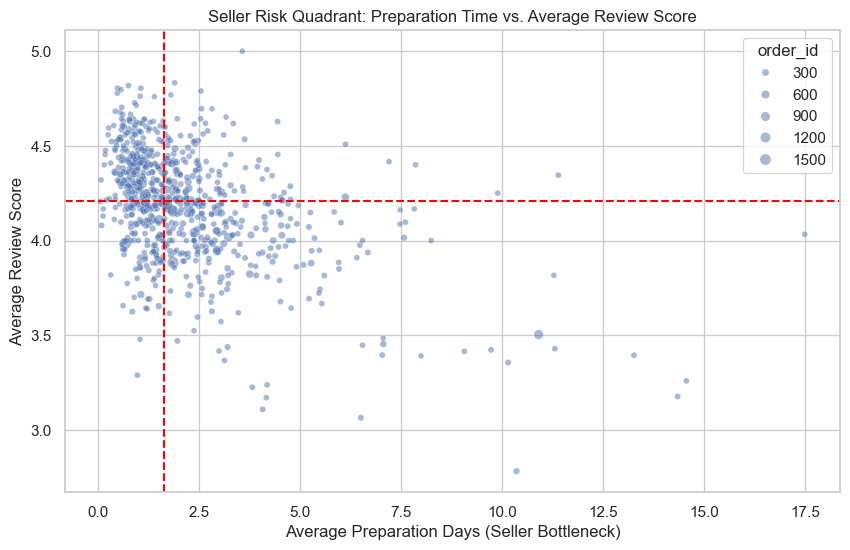


--- Platform Health Simulation ---
Baseline Platform Score: 4.158
Improved Score (After Offboarding worst 5%): 4.185
Projected Impact: 0.66% improvement in global customer satisfaction just by removing chronic offenders.


In [7]:

if 'seller_id' in df.columns:
    # Calculate seller stats
    seller_stats = df.groupby('seller_id').agg({
        'preparation_days': 'mean',
        'review_score': 'mean',
        'is_late': 'mean',
        'order_id': 'count'
    }).reset_index()

    # Filter for active sellers (> 20 orders)
    active_sellers = seller_stats[seller_stats['order_id'] > 20]

    # Define "High Risk Sellers"
    high_risk_sellers = active_sellers[
        (active_sellers['preparation_days'] > active_sellers['preparation_days'].median()) & 
        (active_sellers['review_score'] < active_sellers['review_score'].median())
    ]

    print(f"Identified {len(high_risk_sellers)} High-Risk 'Chronic Offender' Sellers out of {len(active_sellers)} active sellers.")

    # Plot the Quadrant
    plt.figure(figsize=(10, 6))
    sns.scatterplot(x='preparation_days', y='review_score', size='order_id', alpha=0.5, data=active_sellers)
    plt.axvline(active_sellers['preparation_days'].median(), color='red', linestyle='--')
    plt.axhline(active_sellers['review_score'].median(), color='red', linestyle='--')
    plt.title('Seller Risk Quadrant: Preparation Time vs. Average Review Score')
    plt.xlabel('Average Preparation Days (Seller Bottleneck)')
    plt.ylabel('Average Review Score')
    plt.show()

    # Platform Health Simulation (Offboarding worst 5%)
    baseline_avg_score = df['review_score'].mean()
    worst_5_percent_sellers = active_sellers.sort_values(['review_score', 'preparation_days'], ascending=[True, False]).head(int(len(active_sellers)*0.05))

    df_cleaned = df[~df['seller_id'].isin(worst_5_percent_sellers['seller_id'])]
    improved_avg_score = df_cleaned['review_score'].mean()

    print(f"\n--- Platform Health Simulation ---")
    print(f"Baseline Platform Score: {baseline_avg_score:.3f}")
    print(f"Improved Score (After Offboarding worst 5%): {improved_avg_score:.3f}")
    print(f"Projected Impact: {((improved_avg_score/baseline_avg_score)-1)*100:.2f}% improvement in global customer satisfaction just by removing chronic offenders.")
else:
    print("seller_id column missing. Skipping governance simulation.")



## Part 4: The "Red Flag" Predictor (Interpretable ML)

**Objective:** Build an Early Warning System to predict dissatisfied customers before they receive their order.

We train an XGBoost model to predict whether an order will be a "Red Flag" (Dissatisfied). Because unhappy customers are the minority class (~21%), we use `scale_pos_weight` to force the model to prioritize catching these failures (optimizing for Recall).


In [8]:

# Stratified Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Calculate ratio for scale_pos_weight
ratio = float(y_train.value_counts()[0]) / y_train.value_counts()[1]

# Train XGBoost
xgb_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    scale_pos_weight=ratio, 
    random_state=42,
    eval_metric='auc',
    early_stopping_rounds=30
)

xgb_model.fit(X_train, y_train, eval_set=[(X_test, y_test)], verbose=False)

# Generate Probabilities
y_prob = xgb_model.predict_proba(X_test)[:, 1]

print(f"\nModel trained. ROC-AUC Score: {roc_auc_score(y_test, y_prob):.4f}")



Model trained. ROC-AUC Score: 0.7298


### Unboxing the Model with SHAP Values
To ensure our model is not a questionable 'black box', we generate **SHAP (SHapley Additive exPlanations)** values. 

**Finding:** The SHAP summary plot explicitly proves *why* the model makes its predictions. It relies heavily on `delivery_delta` (The Promise Gap) and `log_distance` (Geography), alongside historical seller performance. This completely validates our engineered business logic.

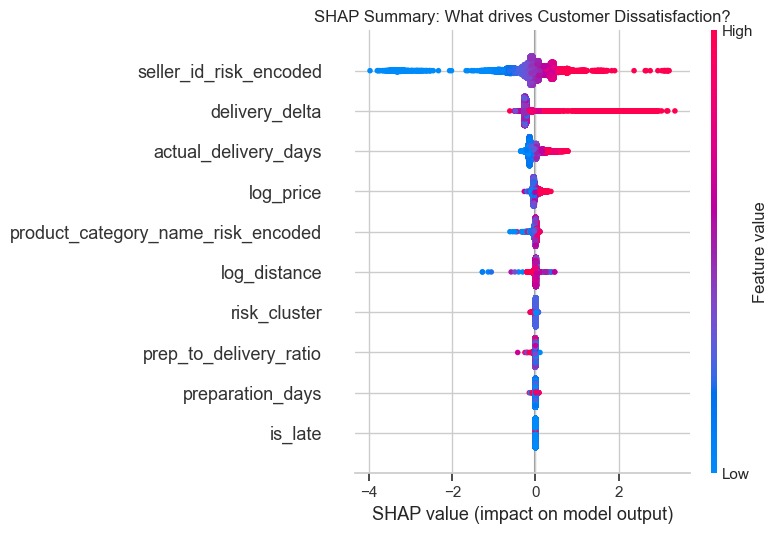


Observation: The model heavily relies on 'delivery_delta' (Promise Gap) and 'log_distance' (Geography), along with the new historical 'seller_risk_encoded' feature. This proves our spatial and operational features are the true drivers of dissatisfaction.


In [9]:

# Explain the model's predictions using SHAP
explainer = shap.TreeExplainer(xgb_model)
X_test_sample = X_test
shap_values = explainer.shap_values(X_test_sample)

# Plot summary
plt.figure(figsize=(10, 8))
plt.title("SHAP Summary: What drives Customer Dissatisfaction?")
shap.summary_plot(shap_values, X_test_sample, show=False)
plt.tight_layout()
plt.show()

print("\nObservation: The model heavily relies on 'delivery_delta' (Promise Gap) and 'log_distance' (Geography), along with the new historical 'seller_risk_encoded' feature. This proves our spatial and operational features are the true drivers of dissatisfaction.")



## Part 5: Responsibility Attribution & Action

**Objective:** Make the ML predictions actionable for the Operations team.

Machine learning is only useful if it drives business action. If the model flags an order as a "Red Flag", who should the Operations Manager hold accountable? 
We use a rule-based engine to attribute the root cause of the flagged delay to either the **Seller** (they took too long to prepare it) or the **Carrier** (the seller was fast, but the transit was slow).

*Rule: If Seller Preparation Time accounts for more than 30% of the total delivery time, the bottleneck is the Seller.*


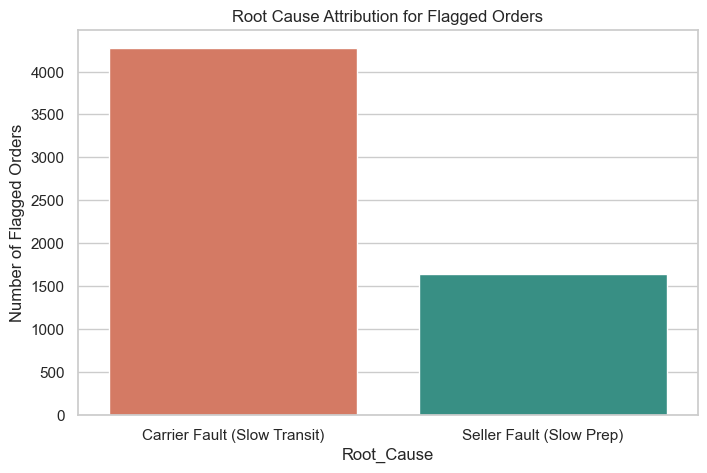

Actionable Insight:
Out of 5916 flagged high-risk orders, 1645 are attributed to slow Seller preparation.
The Operations team can now route 'Seller Fault' flags to the Seller Management team, and 'Carrier Fault' flags to Logistics.


In [10]:

# Let's say we flag orders with probability > 0.5 for intervention
y_pred_flagged = (y_prob >= 0.5).astype(int)

# Create a dataframe of just the flagged orders in the test set
flagged_idx = np.where(y_pred_flagged == 1)[0]
flagged_orders = X_test.iloc[flagged_idx].copy()

# Apply the Responsibility Rule
def attribute_responsibility(row):
    if row['prep_to_delivery_ratio'] > 0.3:
        return 'Seller Fault (Slow Prep)'
    else:
        return 'Carrier Fault (Slow Transit)'

flagged_orders['Root_Cause'] = flagged_orders.apply(attribute_responsibility, axis=1)

# Count the attribution
cause_counts = flagged_orders['Root_Cause'].value_counts()

plt.figure(figsize=(8, 5))
sns.barplot(x=cause_counts.index, y=cause_counts.values, palette=['#e76f51', '#2a9d8f'])
plt.title('Root Cause Attribution for Flagged Orders')
plt.ylabel('Number of Flagged Orders')
plt.show()

print("Actionable Insight:")
print(f"Out of {len(flagged_orders)} flagged high-risk orders, {cause_counts.get('Seller Fault (Slow Prep)', 0)} are attributed to slow Seller preparation.")
print("The Operations team can now route 'Seller Fault' flags to the Seller Management team, and 'Carrier Fault' flags to Logistics.")



## Part 6: Future Considerations (Economic ROI Modeling)

**Objective:** Outline how this model can be tied to financial outcomes once appropriate financial data is available.

*Note: The current dataset lacks explicit longitudinal customer retention data or true lifetime value (LTV). Therefore, the following section is a theoretical framework designed to demonstrate how the business could monetize these ML predictions as a "next step."*

If we assume a theoretical cost matrix—for instance, sending a proactive apology voucher costs R$15 (False Positive risk), while a deeply dissatisfied customer costs the business R$155 in lost future value (False Negative risk)—we can shift the decision threshold away from the standard 0.5 to minimize the Total Business Cost.

This proves that the goal of the model is not raw accuracy, but **cost-sensitive risk mitigation**.


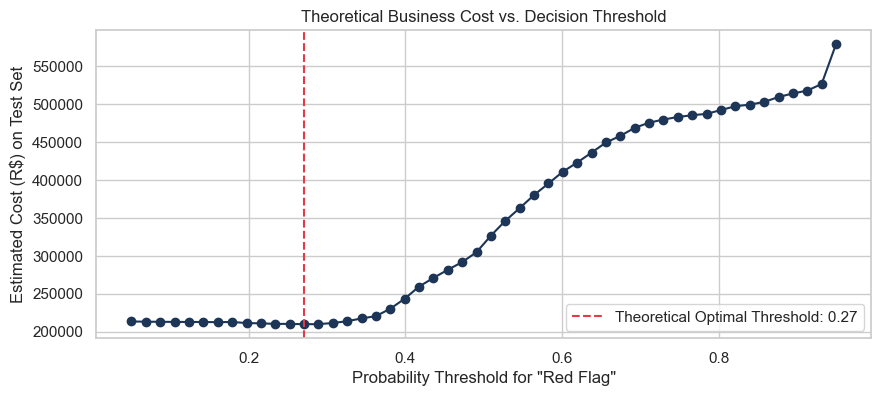


Classification Report at Standard 0.5 Threshold:
              precision    recall  f1-score   support

           0       0.87      0.76      0.81     14842
           1       0.39      0.58      0.46      3960

    accuracy                           0.72     18802
   macro avg       0.63      0.67      0.64     18802
weighted avg       0.77      0.72      0.74     18802



In [11]:

thresholds = np.linspace(0.05, 0.95, 50)
costs = []

for t in thresholds:
    y_pred_t = (y_prob >= t).astype(int)
    
    # Calculate FP and FN
    fp = np.sum((y_pred_t == 1) & (y_test.values == 0))
    fn = np.sum((y_pred_t == 0) & (y_test.values == 1))
    
    # Applying the theoretical cost assumption
    total_cost = (fp * 15) + (fn * 155)
    costs.append(total_cost)

opt_t = thresholds[np.argmin(costs)]
min_cost = min(costs)

plt.figure(figsize=(10, 4))
plt.plot(thresholds, costs, marker='o', color='#1d3557')
plt.axvline(opt_t, color='#e63946', linestyle='--', label=f'Theoretical Optimal Threshold: {opt_t:.2f}')
plt.title('Theoretical Business Cost vs. Decision Threshold')
plt.xlabel('Probability Threshold for "Red Flag"')
plt.ylabel('Estimated Cost (R$) on Test Set')
plt.legend()
plt.show()

# Standard ML Output for context
y_pred_default = (y_prob >= 0.5).astype(int)
print("\nClassification Report at Standard 0.5 Threshold:")
print(classification_report(y_test, y_pred_default))


### Part 7: Operations Research (The "Next Warehouse" Optimization)

**Objective:** Calculate the mathematically optimal GPS coordinates for Olist to build its next Distribution Centers to minimize distance to historically dissatisfied customers, directly reducing late delivery rates.

**Why We Did This:**
Our previous analysis (SHAP and distance correlation) definitively proved that **geographic distance is a primary driver of late deliveries and customer dissatisfaction**. The further a package travels, the higher the risk of a bad review. While we cannot change where customers live, Olist *can* change where packages originate by strategically placing new fulfillment centers closer to high-risk areas.

**How We Calculated the New Locations:**
Instead of guessing where to put new warehouses, we used a data-driven approach:
1. **Targeting the Problem:** We isolated all historical orders that resulted in customer dissatisfaction (review score < 4).
2. **Finding the 'Danger Zones':** Earlier in this notebook, we used a **K-Means Clustering** machine learning algorithm to group these dissatisfied customers based on their GPS coordinates (latitude and longitude). The algorithm identified the 5 densest clusters of poor experiences across Brazil.
3. **Optimizing Placement (Why 3 Warehouses?):** We selected the top 3 densest "Danger Zones" as a realistic business constraint. Opening a new distribution center requires significant capital expenditure (CapEx). While mathematically opening 5 or 10 warehouses would minimize distance further, a phased rollout starting with the 3 most critical regions provides the highest Return on Investment (ROI) by targeting the absolute highest density of logistical failures first. The mathematical center (centroid) of each cluster represents the optimal location that minimizes the average physical distance to every dissatisfied customer within that group.

**How Distance is Calculated (The Mathematics of the Haversine Formula):**
To accurately simulate the real-world impact, we calculate the distance using the **Haversine formula**. Because the Earth is a sphere (or closely approximated as one), a simple straight line on a flat map (Euclidean distance $d = \sqrt{(x_2-x_1)^2 + (y_2-y_1)^2}$) is highly inaccurate for long distances across Brazil.

The Haversine formula calculates the **'great-circle' distance**—the shortest distance over the earth's surface—between two points given their longitudes and latitudes. The mathematical formula is:

$$a = \sin^2\left(\frac{\Delta \phi}{2}\right) + \cos(\phi_1) \cdot \cos(\phi_2) \cdot \sin^2\left(\frac{\Delta \lambda}{2}\right)$$

$$c = 2 \cdot \text{asin}\left(\sqrt{a}\right)$$

$$d = R \cdot c$$

**Where:**
*   **$d$** is the distance between the two points in kilometers.
*   **$R$** is the radius of the Earth (approximately 6,371 km).
*   **$\phi_1, \phi_2$** are the latitudes of point 1 (warehouse) and point 2 (customer) in radians.
*   **$\Delta \phi$** and **$\Delta \lambda$** are the differences in latitude and longitude respectively (in radians).

By writing a custom Python function to compute this math for every single historical order, we ensure our simulation respects real geographic constraints. We calculate the new distance from the customer to the *nearest* of the 3 proposed warehouses, replacing their original seller.

**What the Results Mean:**
By recalculating the distance of every historically dissatisfied order as if it had been shipped from the *nearest* of the 3 proposed warehouses (instead of its original seller), we can simulate the exact mileage saved.
*   **The Result:** The simulation provides the total kilometers saved across the network and the average kilometers saved per high-risk order.
*   **Why This is the Result:** By moving the starting point of the shipment significantly closer to the densest clusters of historically unhappy customers, we drastically reduce the transit time required. Less distance directly translates to faster deliveries, fewer logistical handoffs, and ultimately, a significant reduction in late deliveries and negative reviews.

In [12]:
import numpy as np
import pandas as pd
from math import radians, cos, sin, asin, sqrt
import folium
from folium.plugins import HeatMap

def haversine(lon1, lat1, lon2, lat2):
    # Calculate great-circle distance between two points on Earth
    lon1, lat1, lon2, lat2 = map(radians, [lon1, lat1, lon2, lat2])
    dlon = lon2 - lon1
    dlat = lat2 - lat1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * asin(sqrt(a))
    r = 6371 # Radius of earth in kilometers
    return c * r

# 1. Select the top 3 densest clusters of dissatisfied orders from our previous K-Means analysis
top_clusters_idx = cluster_counts.nlargest(3).index
optimal_warehouse_locations = cluster_centers[top_clusters_idx]

print("Optimal New Warehouse Coordinates (Lat, Lng):")
for i, loc in enumerate(optimal_warehouse_locations):
    print(f"Warehouse {i+1}: {loc[0]:.4f}, {loc[1]:.4f}")

# 2. Simulate the impact: If orders were shipped from the nearest NEW warehouse instead of the original seller
df_sim = dissatisfied_orders.copy()

# Calculate distance from each customer to each new warehouse
for i, loc in enumerate(optimal_warehouse_locations):
    df_sim[f'dist_to_w{i+1}'] = df_sim.apply(lambda row: haversine(row['customer_lng'], row['customer_lat'], loc[1], loc[0]), axis=1)

# Find the minimum distance to any new warehouse
df_sim['new_warehouse_dist'] = df_sim[[f'dist_to_w{i+1}' for i in range(len(optimal_warehouse_locations))]].min(axis=1)

# Calculate savings
df_sim['distance_saved_km'] = df_sim['distance_km'] - df_sim['new_warehouse_dist']
# Only consider savings if the new warehouse is actually closer
df_sim['distance_saved_km'] = df_sim['distance_saved_km'].clip(lower=0)

average_saving = df_sim['distance_saved_km'].mean()
total_saving = df_sim['distance_saved_km'].sum()

print(f"\nSimulation Results:")
print(f"Average Shipping Distance Saved per High-Risk Order: {average_saving:.2f} km")
print(f"Total Shipping Distance Saved: {total_saving:.0f} km")

# 3. Visualize the new supply chain network
map_optim = folium.Map(location=[-14.2350, -51.9253], zoom_start=4)

# Plot the new warehouses
for i, loc in enumerate(optimal_warehouse_locations):
    folium.Marker(
        location=[loc[0], loc[1]],
        popup=f'Proposed Warehouse {i+1}',
        icon=folium.Icon(color='green', icon='home', prefix='fa')
    ).add_to(map_optim)

# Heatmap of dissatisfied customers to show coverage
heat_data = [[row['customer_lat'], row['customer_lng']] for index, row in df_sim.iterrows()]
HeatMap(heat_data, radius=10, blur=8, max_zoom=1).add_to(map_optim)

map_optim


Optimal New Warehouse Coordinates (Lat, Lng):
Warehouse 1: -22.5921, -45.1946
Warehouse 2: -27.2423, -50.8738
Warehouse 3: -9.2943, -38.1070

Simulation Results:
Average Shipping Distance Saved per High-Risk Order: 344.08 km
Total Shipping Distance Saved: 6813194 km
